<a href="https://colab.research.google.com/github/BrianLearning-source/PCVK_Genap_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **WEEK 7**

 **D. Tugas Praktikum**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndimage
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood_fill

3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual

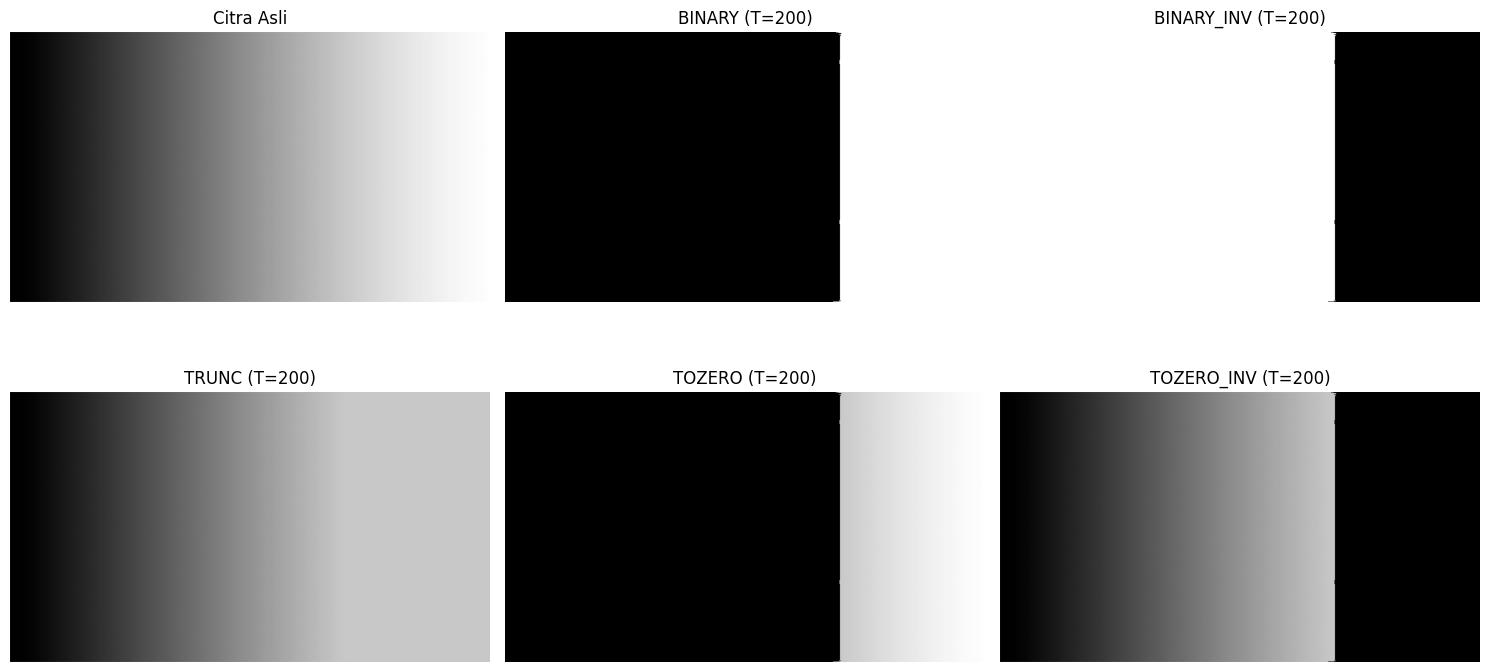

In [12]:
filename = ('/content/drive/MyDrive/PCVK/gradient.jpg')
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
thresh = 200
maxvalue = 255

# 1. Treshold binary, jika nilai pixel > thresh = nilai maks | jika nilai piksel <= tresh = jadi 0

binary = np.where(img > thresh, maxvalue, 0).astype(np.uint8)

# 2. Treshold binary-inverse, jika nilai pixel > thresh = nilai 0 | jika nilai piksel <= tresh = jadi maks

binary_inv = np.where(img > thresh, 0, maxvalue).astype(np.uint8)

# 3. Treshold Truncate, jika nilai pixel > thresh = nilai tresh | jika nilai piksel <= tresh = nilai asli tetap

trunc = np.where(img > thresh, thresh, img).astype(np.uint8)

# 4. Threshold Tozero, jika nilai pixel > thresh = nilai asli tetap | jika nilai piksel <= tresh = jadi 0

tozero = np.where(img > thresh, img, 0).astype(np.uint8)

# 5. Threshold Tozero-Inverse, jika nilai pixel > thresh = nilai 0 | jika nilai piksel <= tresh = asli tetap

tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

titles = [
    'Citra Asli',
    'BINARY (T=200)',
    'BINARY_INV (T=200)',
    'TRUNC (T=200)',
    'TOZERO (T=200)',
    'TOZERO_INV (T=200)'
]

images = [
    img,
    binary,
    binary_inv,
    trunc,
    tozero,
    tozero_inv
]

plt.figure(figsize=(15, 8))

for i, (title, image) in enumerate(zip(titles, images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray', vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()


In [13]:
!apt-get -qq update
!apt-get -qq install
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


Library berhasil diimpor!
Versi OpenCV: 5.0.0
Versi Tesseract: 5.3.4

Silakan unggah gambar KTP dummy.


Saving Gemini_Generated_Image_7mh5g27mh5g27mh5.jpg to Gemini_Generated_Image_7mh5g27mh5g27mh5 (1).jpg
Saving Gemini_Generated_Image_vpehtfvpehtfvpeh.jpg to Gemini_Generated_Image_vpehtfvpehtfvpeh (1).jpg


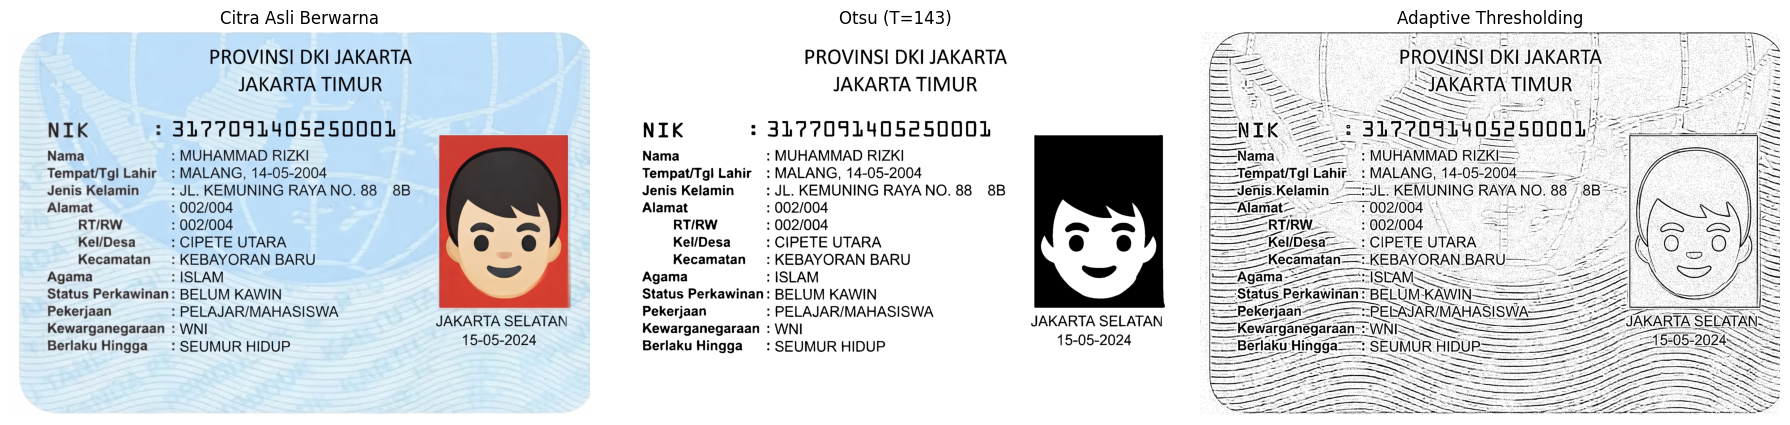


HASIL OCR: Citra Asli Berwarna
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK > 317?091405050001

Nama : MUHAMMAD RIZKI
Tempat/Tgl Lahir : MALANG, 14-05-2004
Jenis Kelamin : JL. KEMUNING RAYA NO. 88 8B

Alamat : 002/004
RT/RW : 002/004
Kel/Desa : CIPETE UTARA
Kecamatan :KEBAYORAN BARU
Agama : ISLAM
Status Perkawinan : BELUM KAWIN
Pekerjaan : PELAJAR/MAHASISWA
Kewarganegarsan-VNI JAKARTA SELATAN
15-05-2024

Berlaku Hingga — : SEUMUR HIDUP


Jumlah potongan teks: 60
Rata-rata confidence: 86.38/100

HASIL OCR: Thresholding Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK > 317?091405050001

Nama : MUHAMMAD RIZKI
Tempat/Tgl Lahir : MALANG, 14-05-2004
Jenis Kelamin : JL. KEMUNING RAYANO. 88 8B

Alamat : 002/004
RT/RW : 002/004
Kel/Desa : CIPETE UTARA
Kecamatan : KEBAYORAN BARU
Agama : ISLAM
Status Perkawinan : BELUM KAWIN
Pekerjaan : PELAJAR/MAHASISWA

Kewarganegaraan : WNI JAKARTA SELATAN
Berlaku Hingga — : SEUMUR HIDUP 15-05-2024


Jumlah potongan teks: 62
Rata-rata confidence: 89.25/100

HASIL OCR

In [19]:

# ============================================================
# TUGAS KELOMPOK P7: PERBANDINGAN OCR PADA CITRA KTP DUMMY
# Citra Asli vs Otsu vs Adaptive Thresholding
# ============================================================

# 1. Instalasi Tesseract dan library
import subprocess
import sys

subprocess.run(
    ["apt-get", "install", "-y", "-qq",
     "tesseract-ocr", "tesseract-ocr-ind"],
    check=True
)

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "pytesseract"],
    check=True
)

# 2. Import library
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

from google.colab import files
from pytesseract import Output

print("Library berhasil diimpor!")
print("Versi OpenCV:", cv.__version__)
print("Versi Tesseract:", pytesseract.get_tesseract_version())

# 3. Unggah citra KTP dummy
print("\nSilakan unggah gambar KTP dummy.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("Tidak ada gambar yang diunggah.")

filename = next(iter(uploaded.keys()))
img_color = cv.imread(filename)

if img_color is None:
    raise ValueError("Gambar gagal dibaca. Periksa format file.")

# Konversi warna dan grayscale
img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

# 4. Thresholding Otsu
otsu_threshold, otsu = cv.threshold(
    img_gray,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# 5. Adaptive Thresholding
adaptive = cv.adaptiveThreshold(
    img_gray,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11,
    2
)

# 6. Tampilkan tiga citra
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

images = [
    ("Citra Asli Berwarna", img_rgb),
    (f"Otsu (T={otsu_threshold:.0f})", otsu),
    ("Adaptive Thresholding", adaptive)
]

for ax, (title, image) in zip(axes, images):
    if len(image.shape) == 2:
        ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(image)

    ax.set_title(title)
    ax.axis("off")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

# 7. Fungsi OCR dan penghitungan confidence
def jalankan_ocr(image, nama_metode):
    print("\n" + "=" * 60)
    print("HASIL OCR:", nama_metode)
    print("=" * 60)

    teks = pytesseract.image_to_string(
        image,
        lang="ind+eng"
    )

    print(teks if teks.strip() else
          "[Tidak ada teks yang berhasil dikenali]")

    data = pytesseract.image_to_data(
        image,
        lang="ind+eng",
        output_type=Output.DATAFRAME
    )

    data = data.dropna(subset=["text"]).copy()
    data["text"] = data["text"].astype(str).str.strip()
    data = data[data["text"] != ""]
    data["conf"] = data["conf"].astype(float)

    # Abaikan baris nonkata dengan confidence negatif
    valid = data[data["conf"] >= 0]

    if len(valid) > 0:
        rata_conf = valid["conf"].mean()
        print(f"\nJumlah potongan teks: {len(valid)}")
        print(f"Rata-rata confidence: {rata_conf:.2f}/100")
    else:
        rata_conf = 0
        print("\nTidak ada potongan teks dengan confidence valid.")

    return teks, data, rata_conf

# 8. Jalankan OCR untuk ketiga metode
hasil_asli = jalankan_ocr(img_color, "Citra Asli Berwarna")
hasil_otsu = jalankan_ocr(otsu, "Thresholding Otsu")
hasil_adaptive = jalankan_ocr(adaptive, "Adaptive Thresholding")

# 9. Ringkasan confidence
print("\n" + "=" * 60)
print("RINGKASAN CONFIDENCE OCR")
print("=" * 60)

print(f"Citra asli : {hasil_asli[2]:.2f}/100")
print(f"Otsu       : {hasil_otsu[2]:.2f}/100")
print(f"Adaptive   : {hasil_adaptive[2]:.2f}/100")

print("\nProses selesai!")
print("Catatan: confidence bukan ukuran akurasi teks yang sesungguhnya.")
